import libs

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


load train datasets

In [2]:
train_df = pd.read_csv("PetFinder-Project-Dataset/train/train.csv")
test_df = pd.read_csv("PetFinder-Project-Dataset/test/test.csv")

breed = pd.read_csv("PetFinder-Project-Dataset/breed_labels.csv")
color = pd.read_csv("PetFinder-Project-Dataset/color_labels.csv")
state = pd.read_csv("PetFinder-Project-Dataset/state_labels.csv")

 Target Variable Distribution & Imbalance

               Count  Percentage (%)
AdoptionSpeed                       
0                410            2.73
1               3090           20.61
2               4037           26.93
3               3259           21.74
4               4197           27.99


C:\Users\a\AppData\Local\Temp\ipykernel_7784\646846617.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=dist_summary.index, y=dist_summary['Count'], palette='viridis')


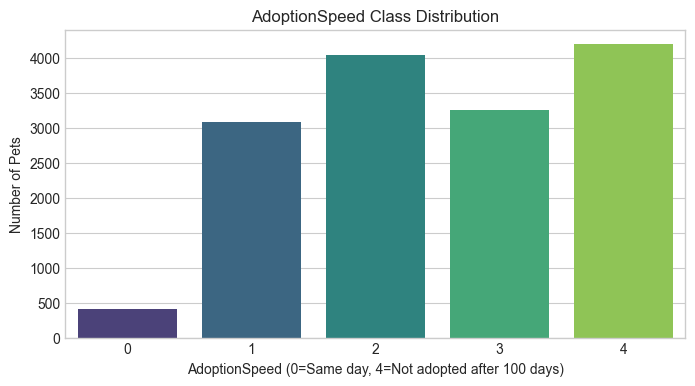

In [18]:
speed_counts = train_df["AdoptionSpeed"].value_counts().sort_index()
speed_pcts = (speed_counts/len(train_df) * 100).round(2)


dist_summary = pd.DataFrame({'Count': speed_counts, 'Percentage (%)': speed_pcts})
print(dist_summary)
plt.style.use('seaborn-v0_8-whitegrid')
plt.figure(figsize=(8, 4))
sns.barplot(x=dist_summary.index, y=dist_summary['Count'], palette='viridis')
plt.title("AdoptionSpeed Class Distribution")
plt.xlabel("AdoptionSpeed (0=Same day, 4=Not adopted after 100 days)")
plt.ylabel("Number of Pets")
plt.show()

Clean Feature Merging & Handling Missing Data

In [35]:
df = train_df.copy()
df["HasName"] = df["Name"].notna() & (~df["Name"].astype(str).str.lower().isin(['no name','unnamed','no name yet']))
df['HasName'] = df['HasName'].astype(int)

color_map = color.set_index('ColorID')['ColorName'].to_dict()

df['Color1'] = df['Color1'].map(color_map).fillna('None')
(df['Color3'] == 0).sum()

10604

In [ ]:
def integrate_lookups_and_clean(df:pd.DataFrame,breed:pd.DataFrame,color:pd.DataFrame,state:pd.DataFrame) -> pd.DataFrame:
    
    df = df.copy()
    df["HasName"] = df["Name"].notna() & (~df["Name"].astype(str).str.lower().isin(['no name','unnamed','no name yet']))
    df['HasName'] = df['HasName'].astype(int)

    

In [ ]:
train_df.head()

,Type,Name,Age,Breed1,Breed2,Gender,Color1,Color2,Color3,MaturitySize,...,Health,Quantity,Fee,State,RescuerID,VideoAmt,Description,PetID,PhotoAmt,AdoptionSpeed
0,2,Nibble,3,299,0,1,1,7,0,1,...,1,1,100,41326,8480853f516546f6cf33aa88cd76c379,0,Nibble is a 3+ month old ball of cuteness. He ...,86e1089a3,1.0,2
1,2,No Name Yet,1,265,0,1,1,2,0,2,...,1,1,0,41401,3082c7125d8fb66f7dd4bff4192c8b14,0,I just found it alone yesterday near my apartm...,6296e909a,2.0,0
2,1,Brisco,1,307,0,1,2,7,0,2,...,1,1,0,41326,fa90fa5b1ee11c86938398b60abc32cb,0,Their pregnant mother was dumped by her irresp...,3422e4906,7.0,3
3,1,Miko,4,307,0,2,1,2,0,2,...,1,1,150,41401,9238e4f44c71a75282e62f7136c6b240,0,"Good guard dog, very alert, active, obedience ...",5842f1ff5,8.0,2
4,1,Hunter,1,307,0,1,1,0,0,2,...,1,1,0,41326,95481e953f8aed9ec3d16fc4509537e8,0,This handsome yet cute boy is up for adoption....,850a43f90,3.0,2
